# Introducción a Gymnasium

Primero se deben importar las librerías necesarias

In [1]:
from IPython.display import display
from PIL import Image
import time 
import gymnasium as gym
import numpy as np 
import matplotlib.pyplot as plt

print(gym.__version__)

1.3.0


Para poder interactuar con un ambiente, es necesario definir el nombre del ambiente y crearlo

In [2]:
env = gym.make("FrozenLake-v1", render_mode = "human") #Cargando el ambiente

Para conocer el número de observaciones y acciones pre-definidas en el ambiente

In [5]:
env.observation_space.n

16

In [6]:
env.action_space.n

4

Con el método action_space.sample() se pueden muestrear una acción aleatoria del espacio de acciones.

In [16]:
action = env.action_space.sample()
print(action)

2


Para interactuar con cualquier ambiente de Gym/Gymnasium se utilizan los siguientes métodos:
* env.reset()
* env.step(action)
* env.render()

Con env.reset() se reinicia el ambiente a su estado/observacion inicial.

In [29]:
observation, info = env.reset()

In [19]:
observation

0

El metódo env.step(action) aplica una acción al ambiente. En el caso de FrozenLake mueve al agente arriba, abajo, izquierda o derecha. Como resultado una nueva observación, la recompensa, un indicador de finalización del episodio, un indicador de truncación del episodio, e información adicional es obtenida.

In [ ]:
action = 1
#0 abajo
#1 derecha
#2
#3

# Pueden usar done o terminated. done para diversos ambientes se define diferente
observation, reward, terminated, truncated, info = env.step(action)
print(observation)
print(reward)
print(terminated)
print(truncated)
print(info)

5
0
True
False
{'prob': 0.33333333333333337}


El método env.render() renderiza el ambiente usando PyGame

In [23]:
env.render()

El método env.close() cierra el ambiente.

In [30]:
env.close()

## Reto 1: Corriendo un episodio
Completa las líneas de código faltante para correr un episodio completo tomando acciones aleatorias

In [2]:
# Cargando el ambiente
env = gym.make("FrozenLake-v1", render_mode = "human") 
env.reset()

done = False
while not done:
    #Mostrar en pantalla
    env.render()
    #Escoger una acción random
    action = env.action_space.sample() 
    #Usar la acción en el ambiente
    observation, reward, done, truncated, info = env.step(action)
#Cerrar el ambiente    
env.close()

## Reto 2: Corriendo varios episodios
Agrega un loop para correr 5 episodios de forma consecutiva tomando acciones aleatorias

In [42]:
# Cargando el ambiente
env = gym.make("FrozenLake-v1", render_mode = "human") 
episodes = 5

for episode in range(episodes):
    #Obteniendo el estado inicial
    env.reset()

    done = False
    while not done:
        #Escoger una acción random
        action = env.action_space.sample() 
        #Usar la acción en el ambiente
        observation, reward, done, truncated, info = env.step(action)
    #Cerrar el ambiente    
env.close()

## Reto 3: Crear un ambiente que no sea resbaladizo
Investigue en la red como crear un ambiente FrozenLake que no sea resbaladizo

In [37]:
env = gym.make("FrozenLake-v1", render_mode = "human", is_slippery=False)
env.reset() #Obteniendo el estado inicial

for step in range(10):
    action = env.action_space.sample()  #Escoger una acción random
    obs,reward,done,truncated,_= env.step(action)   #Usar la acción en el ambiente
env.close()  #Cerrar el ambiente

## Reto 4: Corriendo un episodio con una acción fija
Completa las líneas de código faltantes para correr un episodio completo tomando la acción siempre 1 (corre solo 10 pasos de tiempo)

In [8]:
#Obteniendo el estado inicial
env = gym.make("FrozenLake-v1", render_mode = "human", is_slippery = False)
env.reset()

for step in range(10):
    #Escoger una acción random
    action = 1
    #Usar la acción en el ambiente
    obs,reward,done,truncated,_ = env.step(action)

#Cerrar el ambiente    
env.close()

## Jugando de forma manual

In [9]:
for letra in ['a','b','c', 'd']:
    print(letra)

a
b
c
d


## Reto 5: Función para poder jugar de forma manual
Crea una función que lea la entrada del teclado y devuelva la acción correspondiente según la
#posición de la tecla. Ej. 'd' es acción 1 (down).

In [10]:
def ldru():
    k = input()
    if k == 'l':
        action = 0 #left
    if k == 'd':
        action = 1#down
    if k == 'r': 
        action = 2 #right
    if k == 'u':
        action = 3 #up
        
    return action

## Reto 6: Corriendo un episodio para jugar de forma manual
Carga el ambiente sin hielo y crea una rutina donde se tome la acción seleccionada de forma manual

Imprime la recompensa en cada paso de tiempo y la recompensa acumulada al final del episodio.

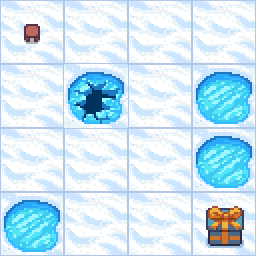

r: 0
Juego terminado
total r: 0


In [11]:
env = gym.make("FrozenLake-v1", render_mode="rgb_array", is_slippery=False)
env.reset()
img = env.render()
display(Image.fromarray(np.array(img), 'RGB'), clear=True)
total_reward = 0

for _ in range(10):
    #Seleccionar acción manual
    #clear_output(wait = True)
    action = ldru()

    #Aplicar la acción en el ambiente
    observation, reward, done, truncated, info = env.step(action)
    total_reward += reward # acumular recompensa

    img = env.render()
    display(Image.fromarray(np.array(img), 'RGB'), clear=True)
    print(f'r: {reward}') # imprimir recompensa

    if done:
        print("Juego terminado")
        break

print(f'total r: {total_reward}') # imprimir recompensa total

## Reto 7: Corriendo un episodio para jugar de forma manual
Carga el ambiente con h crea una rutina donde se tome la acción seleccionada de forma manual

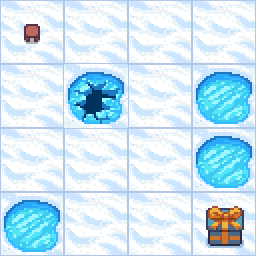

Juego terminado


In [12]:
env = gym.make("FrozenLake-v1", render_mode = "rgb_array", is_slippery=False)
env.reset()
img = env.render()
display(Image.fromarray(np.array(img), 'RGB'), clear=True) 
total_reward = 0
for _ in range(10):
    #clear_output(wait = True)
    action=ldru()
    #Aplicar la acción en el ambiente
    observation, reward, done, truncated, info = env.step(action)
    total_reward += reward # acumular recompensa
    img = env.render()
    display(Image.fromarray(np.array(img), 'RGB'), clear=True) 

    if done:
        print("Juego terminado")
        break